In [ ]:
### STEP 1: IMPORT LIBRARIES AND LOAD DATASET
# In this step, we import the required libraries for model building, evaluation, and visualization.
# Then, we load the student performance dataset.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_curve,
    auc,
    log_loss,
    mean_absolute_error,
    r2_score,
    ConfusionMatrixDisplay
)

# Load the dataset
dfp = '/content/student_performance_dataset.csv'
df = pd.read_csv(dfp)
print("Dataset columns and initial rows:")
display(df.head())
print(df.info())

Dataset columns and initial rows:


,Study_Hours,Attendance,Previous_Marks,Sleep_Hours,Final_Marks,Pass_Status
0,4.37,59.26,48.32,7.36,66.90,1
1,9.56,77.10,47.29,7.98,87.59,1
2,7.59,93.65,93.44,5.25,91.31,1
3,6.39,86.61,47.47,7.12,76.78,1
4,2.40,90.33,49.04,6.86,57.35,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Study_Hours     1000 non-null   float64
 1   Attendance      1000 non-null   float64
 2   Previous_Marks  1000 non-null   float64
 3   Sleep_Hours     1000 non-null   float64
 4   Final_Marks     1000 non-null   float64
 5   Pass_Status     1000 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 47.0 KB
None


In [ ]:
### STEP 2: PREPROCESS DATA AND IDENTIFY TARGET VARIABLES
# Here, we preprocess any categorical variables and split the dataset into features (X)
# and target labels (y) for both classification and regression tasks.

le_dict = {}
for col in df.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    le_dict[col] = le

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
target_reg = None
for potential in ['math score', 'reading score', 'writing score', 'Final_Grade', 'GPA', 'gpa', 'score']:
    match = [c for c in df.columns if potential.lower() in c.lower()]
    if match:
        target_reg = match[0]
        break
if not target_reg:
    target_reg = numeric_cols[-1]

# Create a binary classification target
mean_val = df[target_reg].mean()
classification_target_col = 'Passed_Exam'
df[classification_target_col] = (df[target_reg] >= mean_val).astype(int)

features = [c for c in df.columns if c not in [target_reg, classification_target_col]]

# Split data
X_train, X_test, y_train_reg, y_test_reg = train_test_split(df[features], df[target_reg], test_size=0.2, random_state=42)
_, _, y_train_clf, y_test_clf = train_test_split(df[features], df[classification_target_col], test_size=0.2, random_state=42)

print(f"Regression Target: {target_reg}")
print(f"Classification Target (threshold >= {mean_val:.2f}): {classification_target_col}")

Regression Target: Pass_Status
Classification Target (threshold >= 0.95): Passed_Exam


In [ ]:
### STEP 3: TRAIN CLASSIFIER AND REGRESSOR MODELS
# We train a RandomForestClassifier for the classification task and a RandomForestRegressor
# for the regression task to predict numerical outcomes.

clf_model = RandomForestClassifier(random_state=42, max_depth=5)
clf_model.fit(X_train, y_train_clf)
y_pred_clf = clf_model.predict(X_test)
y_prob_clf = clf_model.predict_proba(X_test)[:, 1]

reg_model = RandomForestRegressor(random_state=42, max_depth=5)
reg_model.fit(X_train, y_train_reg)
y_pred_reg = reg_model.predict(X_test)

In [ ]:
### STEP 4: CALCULATE CLASSIFICATION METRICS
# Here we compute critical metrics for binary classification: Accuracy, Confusion Matrix, Precision, Recall, and Log-loss.

acc = accuracy_score(y_test_clf, y_pred_clf)
prec = precision_score(y_test_clf, y_pred_clf, zero_division=0)
rec = recall_score(y_test_clf, y_pred_clf, zero_division=0)
ll = log_loss(y_test_clf, y_prob_clf)
cm = confusion_matrix(y_test_clf, y_pred_clf)

print("=== Classification Performance Metrics ===")
print(f"1. Accuracy: {acc:.4f}")
print(f"2. Precision: {prec:.4f}")
print(f"3. Recall: {rec:.4f}")
print(f"4. Log-Loss: {ll:.4f}")

=== Classification Performance Metrics ===
1. Accuracy: 1.0000
2. Precision: 1.0000
3. Recall: 1.0000
4. Log-Loss: 0.0076


In [ ]:
### STEP 5: CALCULATE REGRESSION METRICS
# We compute performance evaluation indicators for numerical output: Mean Absolute Deviation (MAD) and Coefficient of Determination (R2).

mad = mean_absolute_error(y_test_reg, y_pred_reg) # MAD is equivalent to MAE
r2 = r2_score(y_test_reg, y_pred_reg)
errors = y_test_reg - y_pred_reg

print("=== Regression Performance Metrics ===")
print(f"5. Mean Absolute Deviation (MAD) Error: {mad:.4f}")
print(f"6. Coefficient of Determination (R2): {r2:.4f}")

=== Regression Performance Metrics ===
5. Mean Absolute Deviation (MAD) Error: 0.0002
6. Coefficient of Determination (R2): 0.9999


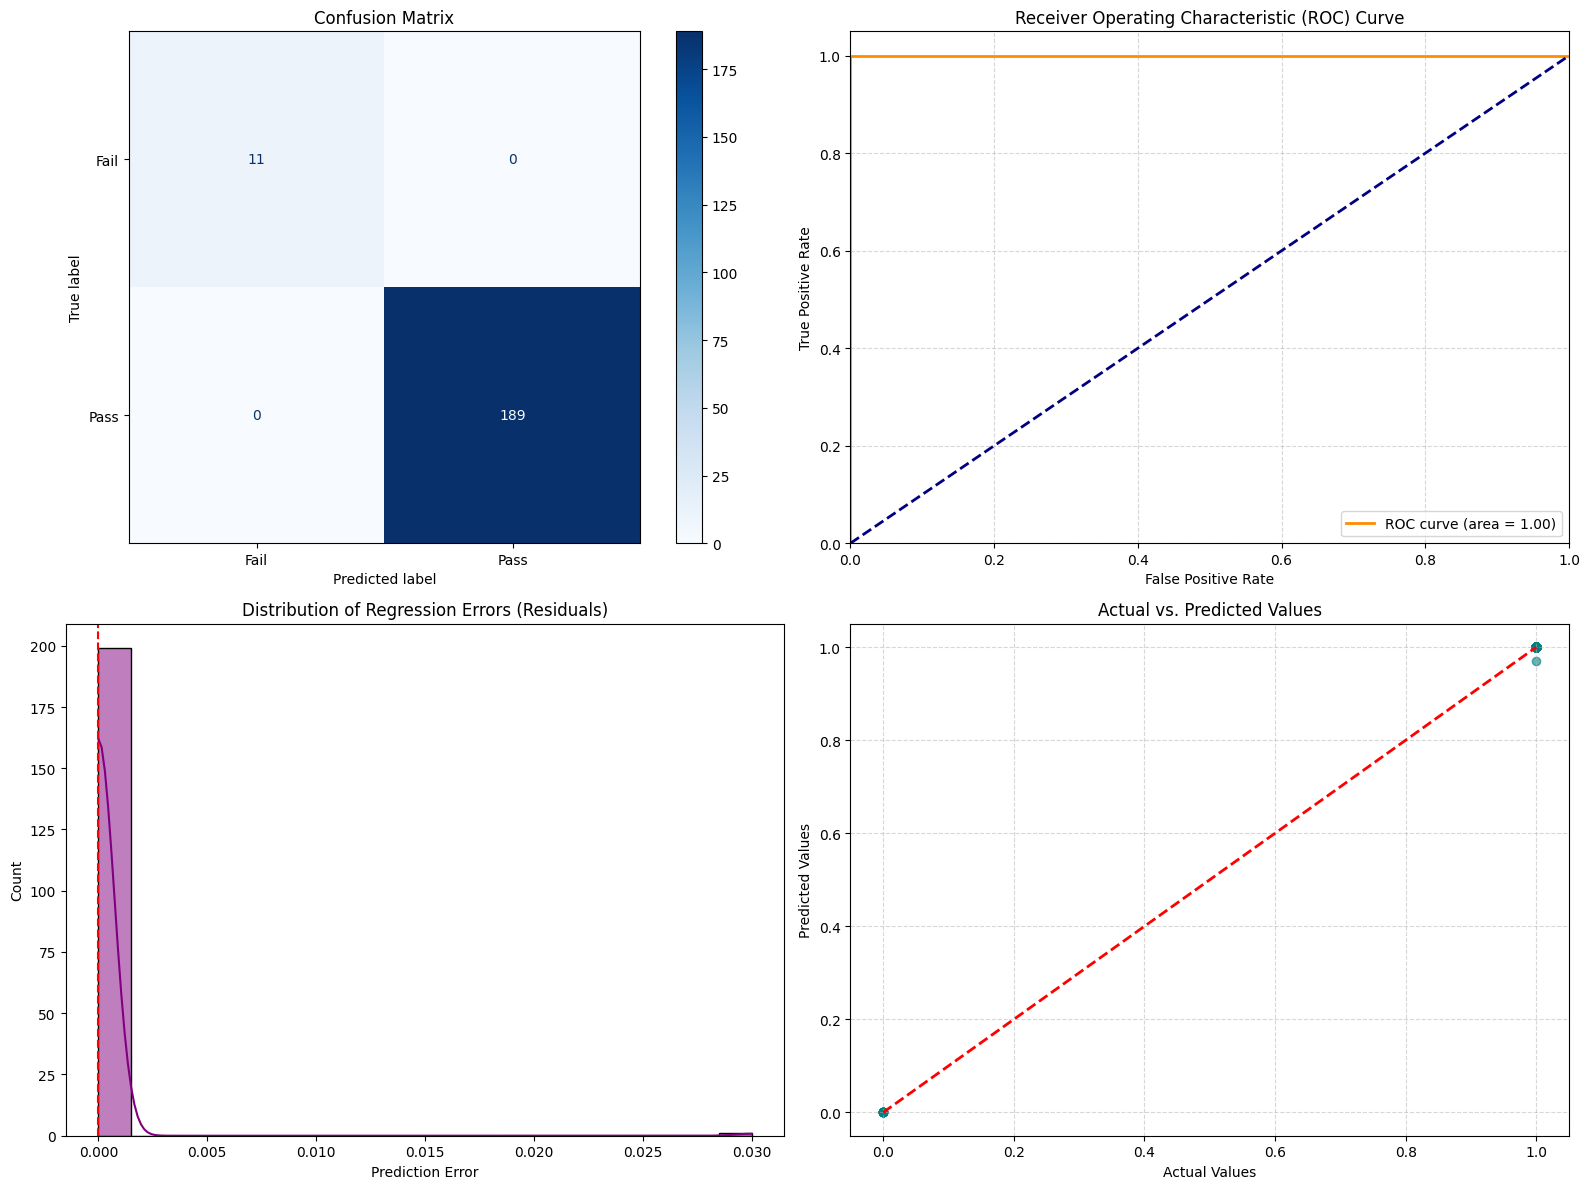

In [ ]:
### STEP 6: VISUALIZE CLASSIFICATION AND REGRESSION PERFORMANCE METRICS
# We plot the Confusion Matrix, ROC Curve, error distribution (residuals), and predicted vs. actual mappings.

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot A: Confusion Matrix
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fail', 'Pass']).plot(ax=axes[0, 0], cmap='Blues', values_format='d')
axes[0, 0].set_title("Confusion Matrix")

# Plot B: ROC Curve
fpr, tpr, _ = roc_curve(y_test_clf, y_prob_clf)
roc_auc = auc(fpr, tpr)
axes[0, 1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
axes[0, 1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0, 1].set_xlim([0.0, 1.0])
axes[0, 1].set_ylim([0.0, 1.05])
axes[0, 1].set_xlabel('False Positive Rate')
axes[0, 1].set_ylabel('True Positive Rate')
axes[0, 1].set_title('Receiver Operating Characteristic (ROC) Curve')
axes[0, 1].legend(loc="lower right")
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# Plot C: Distribution of Errors (Histogram)
sns.histplot(errors, kde=True, ax=axes[1, 0], color='purple', bins=20)
axes[1, 0].axvline(0, color='red', linestyle='--')
axes[1, 0].set_title('Distribution of Regression Errors (Residuals)')
axes[1, 0].set_xlabel('Prediction Error')
axes[1, 0].set_ylabel('Count')

# Plot D: Predicted vs Actual Values
axes[1, 1].scatter(y_test_reg, y_pred_reg, alpha=0.6, color='teal')
axes[1, 1].plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
axes[1, 1].set_xlabel('Actual Values')
axes[1, 1].set_ylabel('Predicted Values')
axes[1, 1].set_title('Actual vs. Predicted Values')
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()